# Job board applications, Jul–Sep 2026
 Put `job-board-applications.csv` next to this notebook.

In [1]:
import numpy as np, pandas as pd, os
import matplotlib.pyplot as plt
pd.set_option('display.width', 200)
rng = np.random.default_rng(42)
SRC = 'job-board-applications.csv'
os.makedirs('output', exist_ok=True)

def wilson(k, n, z=1.96):
    p = k/n; d = 1 + z*z/n
    c = (p + z*z/(2*n))/d; h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return max(c-h, 0), c+h

## 1. Clean the data

In [2]:
raw = pd.read_csv(SRC, keep_default_na=False)
log = {'rows_in': len(raw)}
df = raw.drop_duplicates().copy()
log['exact_duplicates_removed'] = len(raw) - len(df)
assert df.application_id.is_unique

norm = raw.work_mode.str.lower().str.replace('-', '_')
log['work_mode_labels_fixed'] = int((raw.work_mode != norm).sum())
df['work_mode'] = df.work_mode.str.lower().str.replace('-', '_')

df['source'] = df.source.replace('', 'unknown')
log['source_blank_set_unknown'] = int((df.source == 'unknown').sum())

for c in ['shortlisted', 'interviewed', 'hired']:
    df[c] = (df[c] == 'yes').astype(int)
df['reply_days'] = pd.to_numeric(df.days_to_first_reply, errors='coerce')
df['replied'] = df.reply_days.notna().astype(int)
df['paid'] = df.stipend_inr_month > 0
df['all4'] = df.steps_done == 4

# consistency checks, all should be 0
log['hired_without_interview'] = int(((df.hired == 1) & (df.interviewed == 0)).sum())
log['interview_without_shortlist'] = int(((df.interviewed == 1) & (df.shortlisted == 0)).sum())
log['shortlisted_without_reply'] = int(((df.shortlisted == 1) & (df.replied == 0)).sum())
log['rows_out'] = len(df)
pd.Series(log, name='value').to_frame()

,value
rows_in,1206
exact_duplicates_removed,6
work_mode_labels_fixed,9
source_blank_set_unknown,15
hired_without_interview,0
interview_without_shortlist,0
shortlisted_without_reply,0
rows_out,1200


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1200 entries, 0 to 1205
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   application_id       1200 non-null   object 
 1   applied_on           1200 non-null   object 
 2   role_category        1200 non-null   object 
 3   work_mode            1200 non-null   object 
 4   stipend_inr_month    1200 non-null   int64  
 5   source               1200 non-null   object 
 6   steps_done           1200 non-null   int64  
 7   shortlisted          1200 non-null   int32  
 8   interviewed          1200 non-null   int32  
 9   hired                1200 non-null   int32  
 10  days_to_first_reply  1200 non-null   object 
 11  reply_days           966 non-null    float64
 12  replied              1200 non-null   int32  
 13  paid                 1200 non-null   bool   
 14  all4                 1200 non-null   bool   
dtypes: bool(2), float64(1), int32(4), int64(2),

In [4]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
1201    False
1202    False
1203    False
1204    False
1205    False
Length: 1200, dtype: bool

**Fixed:** 6 exact duplicate rows removed; 9 `work_mode` labels standardised (On-site → on_site ); 15 blank sources labelled `unknown`. Logic checks pass.

## Q1. Which source brings the most hires per 100 applications?

In [5]:
def per100(g):
    n, k = len(g), g.hired.sum(); lo, hi = wilson(k, n)
    return pd.Series({'applications': n, 'hires': k, 'hires_per_100': 100*k/n, 'ci_low': 100*lo, 'ci_high': 100*hi})

q1 = df.groupby('source').apply(per100, include_groups=False).sort_values('hires_per_100', ascending=False)
q1.round(1)

,applications,hires,hires_per_100,ci_low,ci_high
source,,,,,
referral,121.0,13.0,10.7,6.4,17.5
email,160.0,13.0,8.1,4.8,13.4
search,439.0,25.0,5.7,3.9,8.3
college,208.0,7.0,3.4,1.6,6.8
social,257.0,6.0,2.3,1.1,5.0
unknown,15.0,0.0,0.0,0.0,20.4


In [6]:
# Is the source effect more than chance? Permutation test (unknown excluded)
known = df[df.source != 'unknown']
def chi(d):
    t = pd.crosstab(d.source, d.hired)
    e = np.outer(t.sum(axis=1), t.sum(axis=0))/t.values.sum()
    return ((t.values - e)**2/e).sum()
obs = chi(known)
perm = [chi(known.assign(source=rng.permutation(known.source.values))) for _ in range(2000)]
print('permutation p-value:', round((np.sum(np.array(perm) >= obs)+1)/2001, 4))

permutation p-value: 0.006


### Does it hold in each role? Hires per 100, and the counts behind it

In [7]:
q1r = df.groupby(['role_category', 'source']).apply(per100, include_groups=False).reset_index()
print('Hires per 100'); display(q1r.pivot(index='role_category', columns='source', values='hires_per_100').round(1))
print('Hires (count)'); display(q1r.pivot(index='role_category', columns='source', values='hires'))
print('Applications'); display(q1r.pivot(index='role_category', columns='source', values='applications'))

Hires per 100


source,college,email,referral,search,social,unknown
role_category,,,,,,
Data,0.0,3.0,4.8,7.4,4.4,0.0
Design,6.7,7.4,23.1,10.6,3.1,NaN
Finance,0.0,0.0,0.0,2.9,0.0,0.0
Marketing,5.6,15.4,22.2,3.8,4.1,0.0
Operations,20.0,5.3,11.1,5.8,0.0,0.0
Software,0.0,11.4,7.0,4.8,1.4,0.0


Hires (count)


source,college,email,referral,search,social,unknown
role_category,,,,,,
Data,0.0,1.0,1.0,6.0,2.0,0.0
Design,2.0,2.0,3.0,5.0,1.0,NaN
Finance,0.0,0.0,0.0,1.0,0.0,0.0
Marketing,2.0,4.0,4.0,3.0,2.0,0.0
Operations,3.0,1.0,2.0,3.0,0.0,0.0
Software,0.0,5.0,3.0,7.0,1.0,0.0


Applications


source,college,email,referral,search,social,unknown
role_category,,,,,,
Data,34.0,33.0,21.0,81.0,45.0,5.0
Design,30.0,27.0,13.0,47.0,32.0,NaN
Finance,20.0,11.0,8.0,34.0,27.0,3.0
Marketing,36.0,26.0,18.0,79.0,49.0,1.0
Operations,15.0,19.0,18.0,52.0,33.0,2.0
Software,73.0,44.0,43.0,146.0,71.0,4.0


**Answer:** referral is best overall (10.7 per 100), then email (8.1), search (5.7), college (3.4), social (2.3). Referral vs email overlap within noise. It is **not** best in every role: Data → search, Software → email, Operations → college (3 hires), Design/Marketing → referral. Each role cell has ≤6 hires, so these are hints, not conclusions.

## Q2. Do applicants who finish all 4 steps get shortlisted more?

In [8]:
def rate(g):
    n, k = len(g), g.shortlisted.sum(); lo, hi = wilson(k, n)
    return pd.Series({'applicants': n, 'shortlisted': k, 'rate_pct': 100*k/n, 'ci_low': 100*lo, 'ci_high': 100*hi})
q2 = df.groupby('all4').apply(rate, include_groups=False); q2.index = ['fewer than 4 steps', 'all 4 steps']
display(q2.round(1))

a, b = df[df.all4].shortlisted.values, df[~df.all4].shortlisted.values
diff = 100*(a.mean()-b.mean())
boot = [100*(rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean()) for _ in range(2000)]
print(f'Difference: {diff:.1f} points, 95% CI {np.percentile(boot,2.5):.1f} to {np.percentile(boot,97.5):.1f}; ratio {a.mean()/b.mean():.1f}x')

,applicants,shortlisted,rate_pct,ci_low,ci_high
fewer than 4 steps,797.0,74.0,9.3,7.5,11.5
all 4 steps,403.0,195.0,48.4,43.5,53.3


Difference: 39.1 points, 95% CI 33.9 to 44.2; ratio 5.2x


In [9]:
print('By steps done'); display(df.groupby('steps_done').apply(rate, include_groups=False).round(1))
print('Shortlist % by role'); display((df.groupby(['role_category','all4']).shortlisted.mean().unstack()*100).round(1).rename(columns={False:'<4 steps', True:'4 steps'}))
print('Shortlist % by paid/unpaid'); display((df.groupby(['paid','all4']).shortlisted.mean().unstack()*100).round(1).rename(columns={False:'<4 steps', True:'4 steps'}))

By steps done


,applicants,shortlisted,rate_pct,ci_low,ci_high
steps_done,,,,,
0,129.0,11.0,8.5,4.8,14.6
1,178.0,10.0,5.6,3.1,10.0
2,248.0,22.0,8.9,5.9,13.1
3,242.0,31.0,12.8,9.2,17.6
4,403.0,195.0,48.4,43.5,53.3


Shortlist % by role


all4,<4 steps,4 steps
role_category,,
Data,10.3,51.6
Design,8.4,57.4
Finance,7.7,47.4
Marketing,10.4,52.3
Operations,14.1,50.0
Software,6.7,41.5


Shortlist % by paid/unpaid


all4,<4 steps,4 steps
paid,,
False,8.9,47.0
True,9.5,49.4


**Answer:** yes. 48.4% vs 9.3%, a gap of about 39 points (CI 34–44), roughly 5×. It holds in every role and for paid and unpaid roles. Steps 0–3 all sit at 6–13%, so the jump happens at step 4. This is a correlation: we can't tell whether finishing causes shortlisting or shortlisting is triggered by finishing.

## Q3. Reply speed: paid vs unpaid

In [10]:
def reply(g):
    r = g.reply_days.dropna(); n, k = len(g), (g.replied == 0).sum(); lo, hi = wilson(k, n)
    return pd.Series({'applications': n, 'no_reply_pct': 100*k/n, 'ci_low': 100*lo, 'ci_high': 100*hi,
                      'median_days': r.median(), 'mean_days': r.mean(), 'p90_days': r.quantile(.9)})
q3 = df.groupby('paid').apply(reply, include_groups=False); q3.index = ['unpaid', 'paid']
q3.round(1)

,applications,no_reply_pct,ci_low,ci_high,median_days,mean_days,p90_days
unpaid,466.0,29.6,25.6,33.9,7.0,7.6,14.0
paid,734.0,13.1,10.8,15.7,3.0,3.2,6.0


In [11]:
# Is the gap just one role, work mode or stipend level?
display(df.groupby(['role_category','paid']).apply(reply, include_groups=False)[['applications','no_reply_pct','median_days']].round(1))
display(df.groupby(['work_mode','paid']).apply(reply, include_groups=False)[['applications','no_reply_pct','median_days']].round(1))
display(df.groupby('stipend_inr_month').apply(reply, include_groups=False)[['applications','no_reply_pct','median_days']].round(1))
print('Replies slower than 14 days:', int((df.reply_days > 14).sum()), '(possible outliers; the medians are not affected)')

applications  no_reply_pct  median_days
role_category paid                                          
Data          False          86.0          27.9          6.0
              True          133.0           6.8          3.0
Design        False          58.0          17.2          7.0
              True           91.0          13.2          3.0
Finance       False          39.0          38.5          6.5
              True           64.0          14.1          2.0
Marketing     False          83.0          31.3          6.0
              True          126.0          12.7          3.0
Operations    False          55.0          32.7          6.0
              True           84.0          15.5          3.0
Software      False         145.0          31.0          7.0
              True          236.0          15.7          3.0

applications  no_reply_pct  median_days
work_mode paid                                          
hybrid    False         153.0          27.5          7.0
          True          224.0          12.1          3.0
on_site   False         113.0          30.1          7.0
          True          199.0          14.1          3.0
remote    False         200.0          31.0          6.0
          True          311.0          13.2          3.0

,applications,no_reply_pct,median_days
stipend_inr_month,,,
0,466.0,29.6,7.0
5000,73.0,8.2,3.0
8000,95.0,14.7,3.0
10000,76.0,7.9,3.0
12000,72.0,18.1,3.0
15000,82.0,15.9,3.0
20000,91.0,11.0,3.0
25000,83.0,16.9,2.0
30000,89.0,7.9,2.0


Replies slower than 14 days: 30 (possible outliers; the medians are not affected)


**Answer:** paid roles reply in a median of 3 days vs 7 for unpaid; 13% of paid and 30% of unpaid applications never get a reply. The gap shows in every role and work mode, and it doesn't grow with stipend size, so it is about paid vs unpaid. That is big enough to act on.

## Chart (answers Q3)

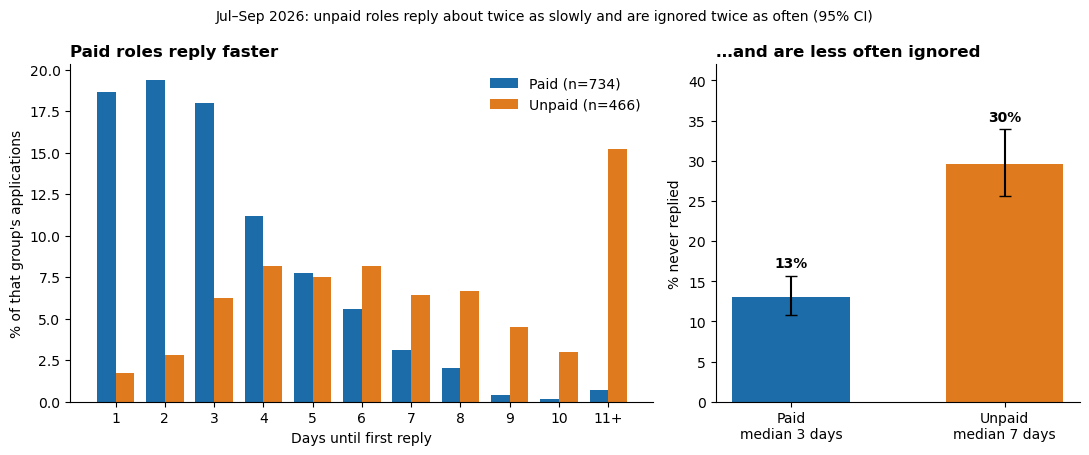

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={'width_ratios': [1.6, 1]})
cols = {'paid': '#1b6ca8', 'unpaid': '#e07a1f'}; w = .38
lab = [str(i) for i in range(1, 11)] + ['11+']
for i, (name, m) in enumerate([('paid', df.paid), ('unpaid', ~df.paid)]):
    g = df[m]; s = g.reply_days.clip(upper=11).value_counts().reindex(range(1, 12), fill_value=0)
    ax[0].bar(np.arange(11) + (i-.5)*w, 100*s.values/len(g), w, color=cols[name], label=f'{name.capitalize()} (n={len(g)})')
ax[0].set_xticks(range(11)); ax[0].set_xticklabels(lab)
ax[0].set_xlabel('Days until first reply'); ax[0].set_ylabel("% of that group's applications")
ax[0].set_title('Paid roles reply faster', loc='left', fontweight='bold'); ax[0].legend(frameon=False)
for i, name in enumerate(['paid', 'unpaid']):
    v, lo, hi = q3.loc[name, ['no_reply_pct', 'ci_low', 'ci_high']]
    ax[1].bar(i, v, .55, color=cols[name], yerr=[[v-lo], [hi-v]], capsize=4)
    ax[1].text(i, hi+1, f'{v:.0f}%', ha='center', fontweight='bold')
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels([f"Paid\nmedian {q3.loc['paid','median_days']:.0f} days", f"Unpaid\nmedian {q3.loc['unpaid','median_days']:.0f} days"])
ax[1].set_ylabel('% never replied'); ax[1].set_ylim(0, 42); ax[1].set_title('…and are less often ignored', loc='left', fontweight='bold')
for a_ in ax: a_.spines[['top', 'right']].set_visible(False)
fig.suptitle('Jul–Sep 2026: unpaid roles reply about twice as slowly and are ignored twice as often (95% CI)', fontsize=10)
plt.tight_layout(); plt.savefig('output/chart_q3_reply_speed.png', dpi=160, bbox_inches='tight'); plt.show()

## Note to manager (~200 words)
See `note_to_manager.md`. Summary: referral is the best source overall but not in every role; finishing all 4 steps goes with a ~39-point higher shortlist rate; unpaid roles reply in 7 vs 3 days and are ignored 30% vs 13% of the time. **Recommendation:** nudge employers on unpaid roles to reply (reminder at day 3, flag at day 7). **Don't trust:** only 64 hires; blank reply may mean "not yet"; stipend 0 may mean "not stated"; Q2 is correlation; synthetic data.